In [2]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'

# import os
# os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'

# This is required to run multiple processes with JAX.
from multiprocessing import set_start_method
set_start_method('forkserver', force=True)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from tqdm import tqdm
from pathlib import Path

# print(jax.devices())
# jax.config.update("jax_debug_nans", True)

from train import Trainer
from config import Config
import data

In [5]:
run_dir = Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled/era5_vae_20260521_231506")
trainer = Trainer.load_last_checkpoint(run_dir)
cfg = trainer.cfg
cfg.quiet = False
cfg.log = False
cfg.num_workers = 0
dls = data.get_dataloaders(cfg, ['train'])

Loading model from /nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled/era5_vae_20260521_231506/checkpoints/step_046400
Model contains 691,938 parameters
Loading trainer from checkpoint step_046400
Logging at /nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled/era5_vae_20260521_231506
Caches will be stored at: /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache0/866e7d7caa86e4c0
Indices for train already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for train...Done!
Dataloader using 0 parallel CPU worker(s).
Indices for validate already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for validate...Done!
Dataloader using 0 parallel CPU worker(s).


In [3]:
cfg_path = Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_pooled/era5_vae.yml")
cfg = Config.from_file(cfg_path)
cfg.quiet = False
cfg.log = False

cfg.num_workers = 0
dls = data.get_dataloaders(cfg)

trainer = Trainer(cfg, dls['train'])

Caches will be stored at: /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache0/866e7d7caa86e4c0
Indices for train already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for train...Done!
Dataloader using 0 parallel CPU worker(s).
Indices for validate already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for validate...Done!
Dataloader using 0 parallel CPU worker(s).
Model contains 691,938 parameters


In [6]:
for batch_meta, batch in tqdm(dls['train']):
    break

  0%|          | 0/1000000000000 [00:46<?, ?it/s]


In [7]:
key = jax.random.PRNGKey(0)

pred = trainer.model(batch, key)
pred.keys()

dict_keys(['discharge', 'vae_ood_score'])

(array([1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 2.3300e+02,
        1.4043e+04, 1.3314e+04, 4.3100e+03, 6.1900e+02, 6.0000e+01]),
 array([-2.62320399, -2.23122048, -1.83923674, -1.44725323, -1.0552696 ,
        -0.66328597, -0.27130237,  0.12068124,  0.51266485,  0.90464842,
         1.29663205]),
 <BarContainer object of 10 artists>)

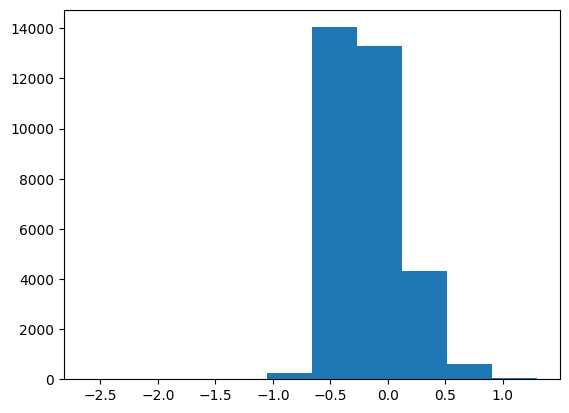

In [11]:
plt.hist(np.log10(pred['vae_ood_score']))

In [12]:
pred['discharge']['log_pi'].shape

(32580, 100)

In [18]:
batch.node_mask[jnp.newaxis, :].shape

(1, 32580)

In [21]:
batch.y['discharge'].shape

(1, 32580, 1)

In [20]:
for k, v in metadata.items():
    print(f"{k}: {v.shape}")

date: (5108,)
reach_id: (5108,)
svs_idx: (5108,)


In [16]:
np.where(batch.d_mask.ravel())

(array([    0,     1,     2, ..., 31279, 31280, 31281]),)

In [13]:
metadata.keys()

dict_keys(['date', 'reach_id', 'svs_idx'])

In [10]:
metadata = batch_meta
row_index = pd.MultiIndex.from_arrays(
        [np.asarray(v) for v in metadata.values()], 
        names=list(metadata.keys())
)

NotImplementedError: > 1 ndim Categorical are not supported at this time

In [6]:
import equinox as eqx
model = trainer.model
model = eqx.nn.inference_mode(model)
key = jax.random.PRNGKey(0)

In [7]:
batch = batch.to_jax()
key, pred_key = jax.random.split(key)
y_pred = model(batch, pred_key)

out_dict = {'metadata': batch_meta, 'y_pred': {}}

ValueError: vmap got inconsistent sizes for array axes to be mapped:
  * most axes (5 of them) had size 31500, e.g. axis 0 of argument batch.x_d of type float32[31500,24];
  * one axis had size 1575: axis 0 of argument batch.x_s of type float32[1575]

In [9]:
debug

> /nas/cee-water/cjgleason/ted/swot-ml/.venv/lib/python3.11/site-packages/jax/_src/api.py(1136)_mapped_axis_size()
   1134     else:
   1135       msg.append(f"  * some axes ({ct} of them) had size {sz}, e.g. axis {ax} of {ex};\n")
-> 1136   raise ValueError(''.join(msg)[:-2])  # remove last semicolon and newline
   1137 
   1138 



ipdb>  up


> /nas/cee-water/cjgleason/ted/swot-ml/src/models/manning_net.py(93)__call__()
     91         keys = jax.random.split(key, batch_size)
     92 
---> 93         return jax.vmap(self.single_reach)(batch, keys)
     94 
     95     def single_reach(self, batch: TabularBatch, key: PRNGKeyArray):

    [... skipped 2 hidden frame(s)]



ipdb>  keys


Array([[ 346279018,  360566543],
       [3968330031, 3923691647],
       [3152301319,  792466127],
       ...,
       [1501701760, 2292303435],
       [3900378571, 2403539085],
       [2074494312,  409269898]], dtype=uint32)


...

ipdb>  batch.x_s


Array([-0.11776749, -0.12147619, -0.1393319 , ..., -0.10490866,
       -0.134758  , -0.1309402 ], dtype=float32)


ipdb>  batch.x_s.shape


(1575,)


ipdb>  q


In [ ]:
target_name = model.target[0]
target_pred = y_pred[target_name]

results = model.summarize_predictions(target_pred, batch.d_mask)

In [ ]:
pd.DataFrame({k: v.ravel() for k, v in results.items()})

In [ ]:
obs_arr = y_obs_dict['gage_q']
obs_arr.shape

In [ ]:
num_obs = obs_arr.shape[-1]
ravel_mask_idx = np.where(batch.d_mask.ravel())[0]
obs_arr.ravel()[ravel_mask_idx].shape

In [ ]:
y_obs_dict = batch.y
pd.DataFrame({k: v.ravel() for k, v in y_obs_dict.items()})

In [ ]:
for k in results.keys():
    print(results[k].shape)

In [ ]:
batch.d_mask.shape

In [ ]:
summary["Q_mean"].ravel()[batch.d_mask.ravel()]

In [ ]:
ravel_mask_idx = np.where(batch.d_mask.ravel())[0]

ravel_mask_idx.shape

In [ ]:
plt.plot(ravel_mask_idx)

In [ ]:
np.where(batch.d_mask)[0].ravel()

In [ ]:
plt.imshow(batch.d_mask)

In [ ]:
a0_est = np.median(target_pred['A0'], axis=-1)

a0_est.shape

In [ ]:
a0_est.shape

In [ ]:
plt.plot(np.tile(a0_est[:,None], 300).ravel())

In [ ]:
y_pred_dict = out_dict['y_pred']
df_parts = {
    "pred": pd.DataFrame({k: v.ravel() for k, v in y_pred_dict.items()})
}

In [ ]:
y_pred_dict['gage_q']

In [ ]:
y_pred_dict['gage_q'].shape

In [ ]:
target_pred['Q'][mask].shape

In [ ]:
import equinox as eqx

model = eqx.tree_at(lambda m: m.return_weights, trainer.model, True)

In [ ]:
key = jax.random.PRNGKey(0)
y_hat, weights = model(batch, key)

In [ ]:
np.where(~np.isnan(batch.dynamic['swot-river'][:,0,0]))

In [ ]:
np.where(~np.isnan(weights['assim']['swot-river']['gain'][:,0,0]))

In [ ]:
batch.dynamic['swot-river'][1,0,:]

In [ ]:
weights['assim']['swot-river']['gain'][1,0,:]

In [ ]:
# params, _ = 
opt_state = optimizer.init(eqx.filter(model, eqx.is_inexact_array))

In [ ]:
opt_state

In [ ]:
getattr(model,'sparse_embedders')

In [ ]:
model.sparse_embedders

In [ ]:
weights['fusion']['weights'].shape

In [ ]:
y_true = batch.y['discharge'][0,...,0]
node_mask = batch.node_mask

valid_mask = (~np.isnan(y_true)) & node_mask
masked_y = np.where(valid_mask, y_true, 0)
expanded_mask = np.expand_dims(valid_mask, axis=-1)

expanded_mask.shape

In [ ]:
np.sum(valid_mask)

In [ ]:
y_hat_target = y_hat['discharge']
masked_y_hat = {
    "mu": jnp.where(expanded_mask, y_hat_target["mu"], 0.0),
    "sigma": jnp.where(expanded_mask, y_hat_target["sigma"], 1.0),  # sigma=1 is safe
    "log_pi": jnp.where(expanded_mask, y_hat_target["log_pi"], 1.0 / y_hat_target["log_pi"].shape[-1]),  # uniform is safe
}

In [ ]:
y_obs = jnp.expand_dims(masked_y, axis=-1)  # Allow broadcasting to each error model
mu = masked_y_hat["mu"]
sigma = masked_y_hat["sigma"]
log_pi = masked_y_hat["log_pi"]

# 1. log(pdf) = -log(sigma) - 0.5*log(2*pi) - 0.5 * ((y-mu)/sigma)^2
log_sigma = jnp.log(sigma)
log_2pi = jnp.log(2.0 * jnp.pi)

# Calculate Mahalanobis distance with clipping
# Gradient of sq_diff w.r.t sigma is proportional to 1/sigma^3. 
# Clipping here is the 'safety valve' for your grad norm.
scaled_diff = (y_obs - mu) / sigma
sq_diff = jnp.square(jnp.clip(scaled_diff, -10.0, 10.0))

log_phi = -log_sigma - 0.5 * log_2pi - 0.5 * sq_diff

# 2. log(sum(pi * pdf)) = logsumexp(log_pi + log_phi)
# Both terms are already in log-space.
log_likelihood = jax.scipy.special.logsumexp(log_pi + log_phi, axis=-1)

# 3. Masked Mean
# Note: sum(mask) + 1e-8 prevents div-by-zero on empty batches
-jnp.sum(log_likelihood * valid_mask) / (jnp.sum(valid_mask) + 1e-8)

In [ ]:
log_pi[valid_mask]

In [ ]:
np.mean(log_weighted_likelihoods, where=valid_mask)

In [ ]:
valid_mask.shape

In [ ]:
y_hat_target['sigma'].shape

In [ ]:
y_hat['sigma'][valid_mask]

In [ ]:
masked_y_hat['sigma'][valid_mask[0,...], :]

In [ ]:
node_mask[jnp.newaxis,:].shape

In [ ]:
log_pi

In [ ]:
-jnp.mean(log_weighted_likelihoods, where=valid_mask)

In [ ]:
valid_mask.shape

In [ ]:
plt.plot(jnp.isnan(log_weighted_likelihoods).T)

In [ ]:
valid_mask.shape

In [ ]:
log_weighted_likelihoods.shape

In [ ]:
import train

train.loss.gmm_nll(masked_y, masked_y_hat, valid_mask, None)

In [ ]:
np.nansum(batch.y['discharge'][0,:,0])

In [ ]:
obs_emb['swot-river'][0].shape

In [ ]:
batch.dynamic['swot-river'].shape

In [ ]:
sub_m

In [ ]:
batch.dynamic['swot-river'][:, batch.node_mask, :]

In [ ]:
batch.node_mask[None,:,None].shape